In [6]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [9]:

img = cv.imread("image.jpg")

# 1. Grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [11]:
# 2. Gaussian Blur
blur = cv.GaussianBlur(gray, (5, 5), 0)

# 3. Gradient Sobel
gx = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
gy = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
gradient = cv.magnitude(gx, gy)

In [13]:

# 4. Canny (Non-Maximum Suppression,
# Double Threshold, Hysteresis)
edges = cv.Canny(blur, 50, 150)

# Affichage
images = [gray, blur, gradient, edges]
titles = ["Grayscale", "Gaussian", "Sobel", "Canny"]

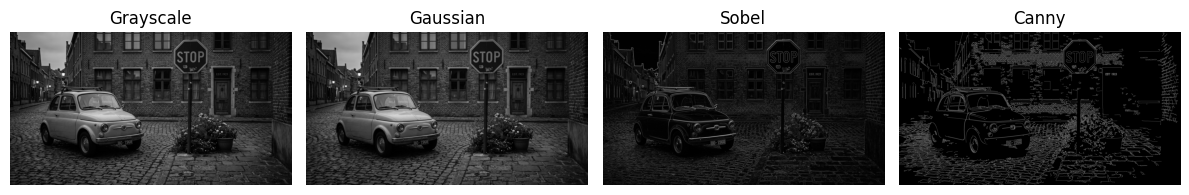

In [14]:
plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

Watershed

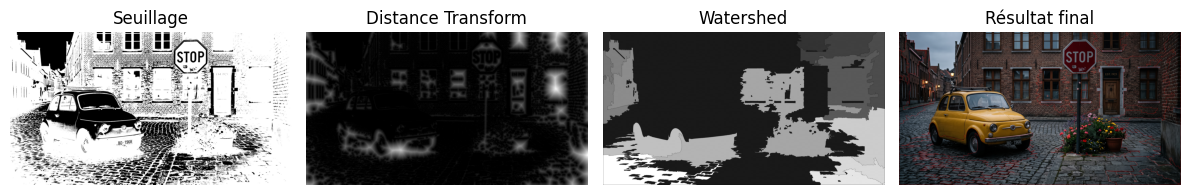

In [28]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


# Lire l'image en couleur et en gris
img = cv.imread("image.jpg")
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. Seuillage Otsu


# 2. Transformation de distance
dist = cv.distanceTransform(binary, cv.DIST_L2, 5)

# 3. Détection des marqueurs
_, fg = cv.threshold(dist, 0.5 * dist.max(), 255, 0)
fg = np.uint8(fg)

bg = cv.dilate(binary, np.ones((3, 3), np.uint8), iterations=3)
unknown = cv.subtract(bg, fg)

_, markers = cv.connectedComponents(fg)
markers = markers + 1
markers[unknown == 255] = 0

# 4. Watershed
markers = cv.watershed(img.copy(), markers)

# 5. Colorier les contours en rouge
result = img.copy()
result[markers == -1] = (0, 0, 255)

# Affichage
images = [binary, dist, markers,
          cv.cvtColor(result, cv.COLOR_BGR2RGB)]

titles = ["Seuillage", "Distance Transform",
          "Watershed", "Résultat final"]


plt.figure(figsize=(12, 4))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap=None if i == 3 else "gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()
